# Parking Space Occupancy Object Detection

**CSCI1409 Deep Learning — Bonus Project**  
Fine-tune a pretrained YOLO11n detector to find each parking space in a full-scene image and label it `free` or `busy`.

This is the only project notebook. It contains the data preparation, grouped split, two-run image-size experiment, held-out evaluation, error review, and prediction demo. The public images and labels must be supplied separately; raw data is too large for Git.


## Before running

Place these assets beside this notebook in the `Project_Parking` folder:

- `CNRPark+EXT.csv`
- `CNR-EXT_FULL_IMAGE_1000x750/` (full-frame images and `camera1.csv` … `camera9.csv`)

The data is from [CNR Parking Dataset](https://cnrpark.it/). Its full-frame archive is about 1.1 GB. In Colab, mount/upload the project folder first. The notebook uses at most 1,600 matched frames, sampled reproducibly with seed 1409.


In [ ]:
%pip install ultralytics==8.4.218 "scikit-learn>=1.5,<2" "numpy>=1.26,<3" "Pillow>=10"


In [ ]:
# Imports and shared settings used throughout this one notebook.
from pathlib import Path
from collections import Counter, defaultdict
from IPython.display import display, Markdown
import csv, json, random, shutil
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import GroupShuffleSplit
from ultralytics import YOLO

SEED = 1409
MAX_IMAGES = 1600
IMAGE_WIDTH, IMAGE_HEIGHT = 1000, 750
ORIGINAL_WIDTH, ORIGINAL_HEIGHT = 2592, 1944
EPOCHS, BATCH_SIZE = 15, 8
PROJECT = Path.cwd()
FRAMES = PROJECT / "CNR-EXT_FULL_IMAGE_1000x750" / "FULL_IMAGE_1000x750"
OCCUPANCY_CSV = PROJECT / "CNRPark+EXT.csv"
DATA = PROJECT / "data" / "parking_yolo"
RUN_DIR = PROJECT / ".parking_training_tmp"  # Temporary Ultralytics checkpoints/logs; removed at the end.
FINAL_WEIGHTS = PROJECT / "parking_yolo11n.pt"
DEVICE = "mps" if torch.backends.mps.is_available() else (0 if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
print("Project:", PROJECT.resolve())
print("Device:", DEVICE)
print("Occupancy CSV found:", OCCUPANCY_CSV.exists())
print("Full-frame folder found:", FRAMES.exists())
assert OCCUPANCY_CSV.exists() and FRAMES.exists(), "Put the two dataset assets next to this notebook first."


## 1. Join occupancy labels to full-frame parking-space boxes

`CNRPark+EXT.csv` gives free/busy state by camera, timestamp, and slot ID. Each `cameraN.csv` gives the fixed rectangle for that slot. The code below matches those three keys, rescales coordinates from 2592×1944 to the released 1000×750 frames, then writes YOLO label files. It skips any frame without a complete set of slot labels.


In [ ]:
# Convert timestamp strings to digits so formats like 2015-11-12_07.17
# and image names like 2015-11-12_0717 use the same join key.
def digits(value):
    return "".join(char for char in value if char.isdigit())

with OCCUPANCY_CSV.open(newline="", encoding="utf-8-sig") as f:
    occupancy_rows = list(csv.DictReader(f))
occupancy = defaultdict(dict)
for row in occupancy_rows:
    camera = row["camera"].zfill(2)
    timestamp = digits(row["datetime"])
    occupancy[(camera, timestamp)][row["slot_id"]] = row["occupancy"]

# Load fixed slot rectangles for each of the nine cameras.
geometries = {}
for camera_number in range(1, 10):
    geometry_file = PROJECT / "CNR-EXT_FULL_IMAGE_1000x750" / f"camera{camera_number}.csv"
    with geometry_file.open(newline="") as f:
        geometries[f"{camera_number:02d}"] = list(csv.DictReader(f))

candidates = []
for image in FRAMES.rglob("*.jpg"):
    camera = image.parent.name.replace("camera", "").zfill(2)
    timestamp = digits(image.stem)
    states = occupancy.get((camera, timestamp))
    slots = geometries.get(camera, [])
    if states and len(states) == len(slots) and all(slot["SlotId"] in states for slot in slots):
        candidates.append((image, camera, timestamp, states, slots))
assert len(candidates) >= MAX_IMAGES, f"Only {len(candidates)} frames matched the labels."

# A fixed sample seed makes the same 1,600 images selectable on rerun.
rng = random.Random(SEED)
candidates = sorted(candidates, key=lambda item: str(item[0]))
selected = sorted(rng.sample(candidates, MAX_IMAGES), key=lambda item: str(item[0]))

# Split by date rather than individual frames to avoid near-duplicate scenes
# from the same day appearing in both training and evaluation.
groups = [item[0].parts[-3] for item in selected]
indices = list(range(len(selected)))
outer = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
trainval_idx, test_idx = next(outer.split(indices, groups=groups))
inner = GroupShuffleSplit(n_splits=1, test_size=0.1875, random_state=SEED)
train_rel, val_rel = next(inner.split(trainval_idx, groups=[groups[i] for i in trainval_idx]))
split_indices = {int(i): "train" for i in trainval_idx[train_rel]}
split_indices.update({int(i): "val" for i in trainval_idx[val_rel]})
split_indices.update({int(i): "test" for i in test_idx})

# Rebuild only the generated YOLO subset, never alter the downloaded raw data.
if DATA.exists():
    shutil.rmtree(DATA)
for split_name in ("train", "val", "test"):
    (DATA / "images" / split_name).mkdir(parents=True, exist_ok=True)
    (DATA / "labels" / split_name).mkdir(parents=True, exist_ok=True)

manifest = []
for index, (image, camera, timestamp, states, slots) in enumerate(selected):
    split_name = split_indices[index]
    filename = f"cam{camera}_{timestamp}.jpg"
    shutil.copy2(image, DATA / "images" / split_name / filename)
    label_lines = []
    for slot in slots:
        # Scale the source box to the actual 1000x750 image before normalizing.
        x = float(slot["X"]) * IMAGE_WIDTH / ORIGINAL_WIDTH
        y = float(slot["Y"]) * IMAGE_HEIGHT / ORIGINAL_HEIGHT
        w = float(slot["W"]) * IMAGE_WIDTH / ORIGINAL_WIDTH
        h = float(slot["H"]) * IMAGE_HEIGHT / ORIGINAL_HEIGHT
        class_id = 1 if states[slot["SlotId"]] == "1" else 0  # 0=free, 1=busy
        cx, cy = x + w / 2, y + h / 2
        label_lines.append(f"{class_id} {cx/IMAGE_WIDTH:.6f} {cy/IMAGE_HEIGHT:.6f} {w/IMAGE_WIDTH:.6f} {h/IMAGE_HEIGHT:.6f}")
    (DATA / "labels" / split_name / f"{Path(filename).stem}.txt").write_text("\n".join(label_lines) + "\n")
    manifest.append({"file": filename, "source": str(image.relative_to(PROJECT)),
                     "camera": camera, "datetime": timestamp, "date": image.parts[-3],
                     "split": split_name, "slot_count": len(slots)})

with (DATA / "manifest.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=manifest[0].keys())
    writer.writeheader(); writer.writerows(manifest)
DATA_YAML = DATA / "dataset.yaml"
DATA_YAML.write_text(f"path: {DATA.resolve()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: free\n  1: busy\n")
print(f"Matched frames: {len(candidates)}; selected frames: {len(selected)}")


In [ ]:
# Show exact split sizes, date groups, and free/busy box counts for the report.
for split_name in ("train", "val", "test"):
    rows = [row for row in manifest if row["split"] == split_name]
    class_counts = Counter()
    for row in rows:
        label_path = DATA / "labels" / split_name / f"{Path(row['file']).stem}.txt"
        for line in label_path.read_text().splitlines():
            class_counts[int(line.split()[0])] += 1
    print(f"{split_name}: {len(rows)} images; {class_counts[0]} free boxes; {class_counts[1]} busy boxes; dates={sorted({r['date'] for r in rows})}")

# Assert no calendar date is shared between the three splits.
dates_by_split = {s: {r["date"] for r in manifest if r["split"] == s} for s in ("train", "val", "test")}
assert not (dates_by_split["train"] & dates_by_split["val"] or dates_by_split["train"] & dates_by_split["test"] or dates_by_split["val"] & dates_by_split["test"])


## 2. Fine-tune YOLO11n and compare image sizes

Both runs start from the same pretrained `yolo11n.pt` weights and use the same split, seed, batch size, and 15 epochs. The only planned change is image size: 640 versus 800. We select using validation mAP@0.50, then evaluate only the selected run on the held-out test set. Real metric tables and Matplotlib curves are embedded below.


**Selected on validation:** `experiment_800` (imgsz=800, 15 epochs).

| Run | imgsz | Val P | Val R | Val mAP50 | Val mAP50:95 | Test P | Test R | Test mAP50 | Test mAP50:95 |
|---|---|---|---|---|---|---|---|---|---|
| baseline_640 | 640 | 0.986 | 0.957 | 0.991 | 0.756 | — | — | — | — |
| experiment_800 | 800 | 0.983 | 0.969 | 0.992 | 0.786 | 0.989 | 0.973 | 0.993 | 0.786 |

Test metrics of the selected model: precision **0.989**, recall **0.973**, mAP@0.50 **0.993**, mAP@0.50:0.95 **0.786**.

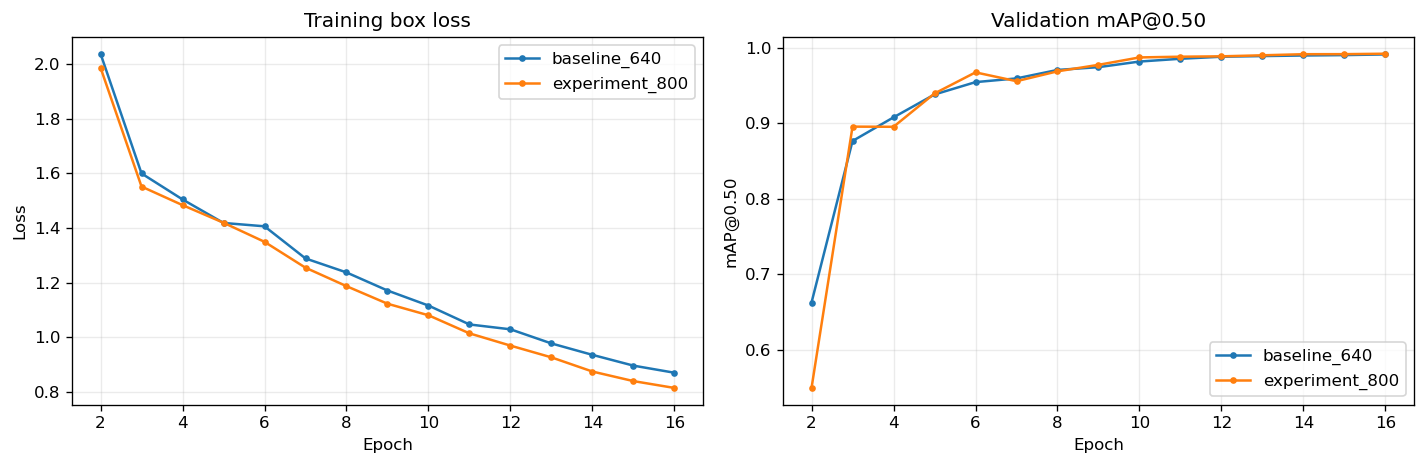

Final model saved as: parking_yolo11n.pt


In [8]:
runs = []
RUN_DIR.mkdir(parents=True, exist_ok=True)
for run_name, image_size in (("baseline_640", 640), ("experiment_800", 800)):
    # Reload identical pretrained weights, changing only the image size.
    model = YOLO("yolo11n.pt")
    model.train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=image_size, batch=BATCH_SIZE,
                device=DEVICE, workers=0, seed=SEED, deterministic=True,
                patience=5, optimizer="auto", project=str(RUN_DIR), name=run_name,
                exist_ok=True, plots=False, save=True, verbose=True)
    best_path = RUN_DIR / run_name / "weights" / "best.pt"
    best_model = YOLO(str(best_path))
    val = best_model.val(data=str(DATA_YAML), split="val", imgsz=image_size,
                         batch=BATCH_SIZE, device=DEVICE, workers=0, plots=False,
                         project=str(RUN_DIR), name=f"{run_name}_validation", exist_ok=True)
    runs.append({"run": run_name, "imgsz": image_size, "epochs": EPOCHS,
                 "weights_path": best_path,
                 "validation": {"precision": float(val.box.mp), "recall": float(val.box.mr),
                                "map50": float(val.box.map50), "map50_95": float(val.box.map)}})
    print(f"{run_name} validation:", runs[-1]["validation"])

# Select the image-size setting using validation only; test the selected run once.
chosen = max(runs, key=lambda run: run["validation"]["map50"])
selected_model = YOLO(str(chosen["weights_path"]))
test = selected_model.val(data=str(DATA_YAML), split="test", imgsz=chosen["imgsz"],
                          batch=BATCH_SIZE, device=DEVICE, workers=0, plots=False,
                          project=str(RUN_DIR), name="selected_test", exist_ok=True)
chosen["test"] = {"precision": float(test.box.mp), "recall": float(test.box.mr),
                  "map50": float(test.box.map50), "map50_95": float(test.box.map)}
shutil.copy2(chosen["weights_path"], FINAL_WEIGHTS)

# Display the experiment table directly in the notebook instead of saving a report file.
rows = []
for run in runs:
    test_values = run.get("test", {})
    rows.append([run["run"], run["imgsz"], f"{run['validation']['precision']:.3f}",
                 f"{run['validation']['recall']:.3f}", f"{run['validation']['map50']:.3f}", f"{run['validation']['map50_95']:.3f}",
                 f"{test_values.get('precision', float('nan')):.3f}" if test_values else "—",
                 f"{test_values.get('recall', float('nan')):.3f}" if test_values else "—",
                 f"{test_values.get('map50', float('nan')):.3f}" if test_values else "—",
                 f"{test_values.get('map50_95', float('nan')):.3f}" if test_values else "—"])
headers = ["Run", "imgsz", "Val precision", "Val recall", "Val mAP50", "Val mAP50:95", "Test precision", "Test recall", "Test mAP50", "Test mAP50:95"]
md_table = "| " + " | ".join(headers) + " |\n|" + "|".join(["---"]*len(headers)) + "|\n"
md_table += "\n".join("| " + " | ".join(row) + " |" for row in rows)
display(Markdown(f"**Selected by validation mAP@0.50:** `{chosen['run']}`\n\n{md_table}\n\nTest mAP@0.50: **{chosen['test']['map50']:.3f}** · Test mAP@0.50:0.95: **{chosen['test']['map50_95']:.3f}**"))

# Plot training loss and validation mAP directly below this cell.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run in runs:
    with (RUN_DIR / run["run"] / "results.csv").open(newline="") as f:
        history = list(csv.DictReader(f))
    epochs = [int(row["epoch"]) + 1 for row in history]
    axes[0].plot(epochs, [float(row["train/box_loss"]) for row in history], label=run["run"])
    axes[1].plot(epochs, [float(row["metrics/mAP50(B)"]) for row in history], label=run["run"])
axes[0].set(title="Training box loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Validation mAP@0.50", xlabel="Epoch", ylabel="mAP@0.50")
for ax in axes: ax.grid(alpha=.25); ax.legend()
plt.tight_layout(); plt.show()
print("Final model saved as:", FINAL_WEIGHTS.name)


## 3. Review test-set failures and inspect predictions

A deterministic sample of 24 held-out frames is reviewed at confidence 0.25 and IoU 0.50. This visual error audit is separate from the full test-set detector metrics above. Outputs display inline in this notebook.


Deterministic visual audit: 24 of 347 held-out frames; confidence ≥0.25, IoU ≥0.50. Errors in this sample — missed: 5, extra: 70, wrong class: 3.


| Sample frame | Missed | Extra | Wrong class |
|---|---:|---:|---:|
| cam09_201511211317.jpg | 0 | 5 | 1 |
| cam01_201511160910.jpg | 3 | 3 | 0 |
| cam07_201511271419.jpg | 0 | 6 | 0 |
| cam07_201601161013.jpg | 0 | 6 | 0 |
| cam08_201511271032.jpg | 0 | 4 | 1 |

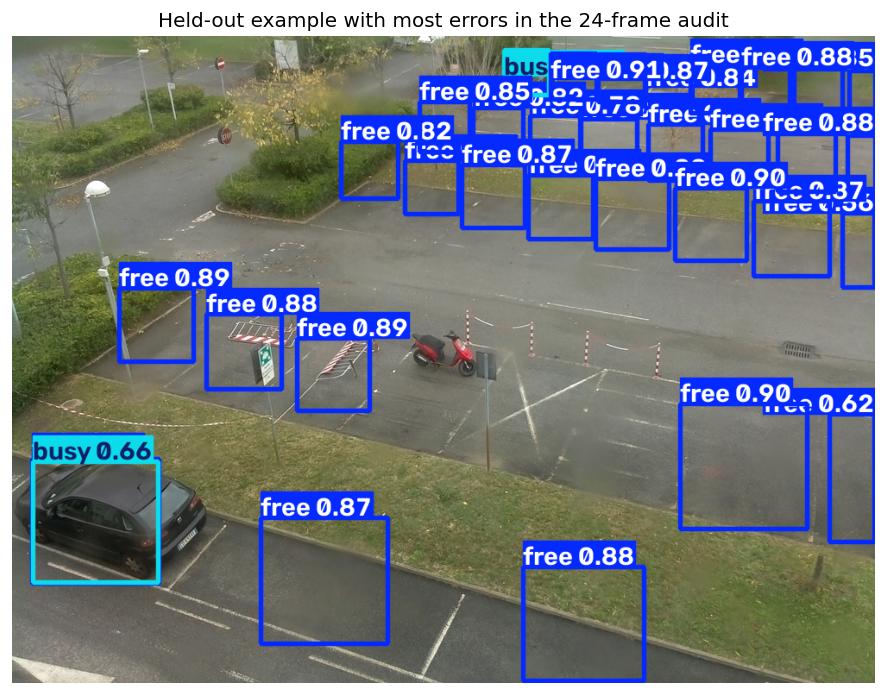

In [10]:
# Match predicted and true boxes greedily by IoU to summarize test errors.
def box_iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    intersection = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    return intersection / max(area_a + area_b - intersection, 1e-9)

CONFIDENCE, IOU_THRESHOLD = 0.25, 0.50
image_paths = sorted((DATA / "images" / "test").glob("*.jpg"))
review_paths = image_paths[::max(1, len(image_paths)//24)][:24]  # Deterministic sample.
totals = Counter(); error_frames = []
for path in review_paths:
    result = selected_model.predict(source=str(path), imgsz=chosen["imgsz"], conf=CONFIDENCE,
                                    device="cpu", verbose=False, save=False)[0]
    height, width = result.orig_shape
    truths = []
    for line in (DATA / "labels" / "test" / f"{path.stem}.txt").read_text().splitlines():
        cls, cx, cy, bw, bh = map(float, line.split())
        truths.append((int(cls), [(cx-bw/2)*width, (cy-bh/2)*height, (cx+bw/2)*width, (cy+bh/2)*height]))
    preds = []
    if result.boxes is not None:
        for box, cls in zip(result.boxes.xyxy.cpu().numpy(), result.boxes.cls.cpu().numpy().astype(int)):
            preds.append((int(cls), box.tolist()))
    pairs = sorted(((box_iou(gt[1], pred[1]), gi, pi) for gi, gt in enumerate(truths) for pi, pred in enumerate(preds)), reverse=True)
    used_gt, used_pred, matches = set(), set(), []
    for overlap, gi, pi in pairs:
        if overlap < IOU_THRESHOLD: break
        if gi not in used_gt and pi not in used_pred:
            used_gt.add(gi); used_pred.add(pi); matches.append((gi, pi, overlap))
    class_errors = [(gi, pi) for gi, pi, _ in matches if truths[gi][0] != preds[pi][0]]
    missed = len(truths) - len(used_gt); false_positives = len(preds) - len(used_pred)
    totals.update({"ground_truth_boxes": len(truths), "predicted_boxes": len(preds),
                   "class_errors": len(class_errors), "missed_boxes": missed,
                   "false_positive_boxes": false_positives})
    if missed or false_positives or class_errors:
        error_frames.append({"image": path.name, "missed": missed, "false_positives": false_positives,
                             "wrong_classes": len(class_errors), "gt_boxes": len(truths), "predicted_boxes": len(preds)})
error_frames.sort(key=lambda r: (r["missed"]+r["false_positives"]+2*r["wrong_classes"], r["gt_boxes"]), reverse=True)
print(f"Sample test error review (confidence ≥ {CONFIDENCE}, IoU ≥ {IOU_THRESHOLD}):", dict(totals))
if error_frames:
    headers = ["Test frame", "Missed", "Extra", "Wrong class"]
    rows = [[r["image"], r["missed"], r["false_positives"], r["wrong_classes"]] for r in error_frames[:5]]
    table = "| " + " | ".join(headers) + " |\n|---|---:|---:|---:|\n"
    table += "\n".join("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown(table))
    # Display one error case inline without saving a figure or report.
    failure_path = DATA / "images" / "test" / error_frames[0]["image"]
    failure_result = selected_model.predict(source=str(failure_path), imgsz=chosen["imgsz"],
        conf=CONFIDENCE, device=DEVICE, save=False, verbose=False)[0]
    plt.figure(figsize=(12, 7)); plt.imshow(failure_result.plot()[:, :, ::-1]); plt.axis("off")
    plt.title("Highest-error held-out frame · predicted boxes"); plt.show()


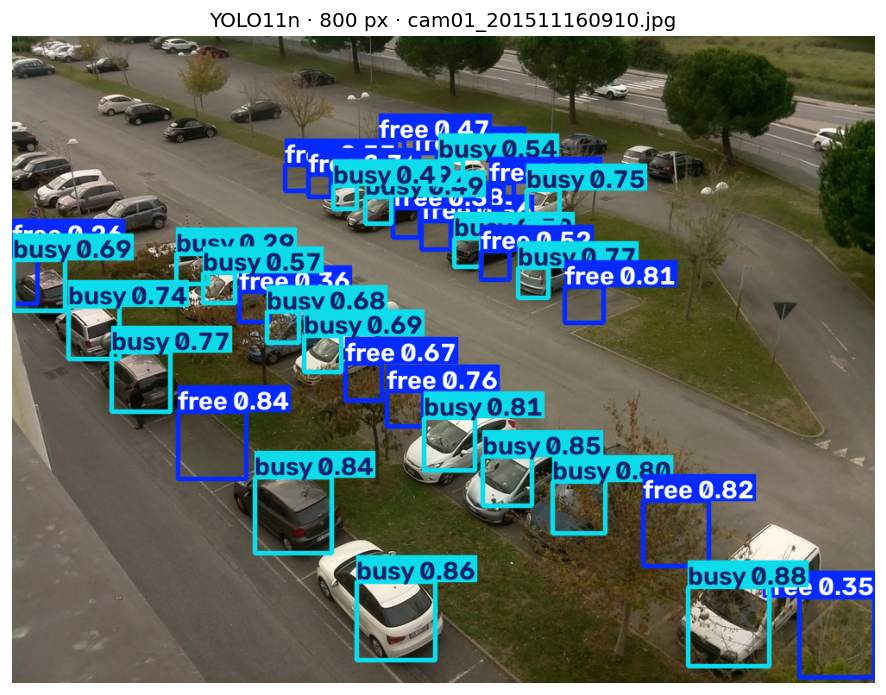

In [11]:
# Change this Path to a local full-scene photo to try inference.
# Campus accuracy has not been evaluated, so treat those predictions as a demo.
IMAGE_TO_PREDICT = image_paths[0]
prediction = selected_model.predict(source=str(IMAGE_TO_PREDICT), imgsz=chosen["imgsz"],
                                    device=DEVICE, save=False, verbose=False)[0]
plt.figure(figsize=(12, 7)); plt.imshow(prediction.plot()[:, :, ::-1]); plt.axis("off")
plt.title(f"Parking spaces: free / busy · {IMAGE_TO_PREDICT.name}"); plt.show()


## Interpretation and limitations

- A box means a **parking space**, not a vehicle. The box position comes from the dataset's fixed slot layout; the model predicts its free/busy label.
- The split holds out calendar dates, but all splits share the same nine cameras and the same physical parking lot.
- This public-data prototype has not been tested on our university's parking lot. A campus camera needs its own slot calibration and local evaluation before results can be trusted.
- YOLO11 is provided by Ultralytics; check its license before redistributing weights. CNRPark+EXT data is licensed under ODbL 1.0. See [CNR dataset](https://cnrpark.it/) and [YOLO11 documentation](https://docs.ultralytics.com/models/yolo11).


In [13]:
# Remove temporary Ultralytics logs, plots, and intermediate checkpoints.
if RUN_DIR.exists():
    shutil.rmtree(RUN_DIR)
print("Training charts and metric tables are embedded in this notebook; final model weights:", FINAL_WEIGHTS.name)


Training charts and metric tables are embedded in this notebook; final model weights: parking_yolo11n.pt
